In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd() if (pathlib.Path.cwd() / 'cartpole.py').exists() else pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np, cartpole as cp
from controllers import lqr_discrete

P = cp.CartPoleParams(); A, B = cp.analytic_AB(P); dt = 0.02; A_d, B_d = cp.discretize(A, B, dt)
Q = np.diag([4.0, 1.0, 25.0, 1.0]); R = np.array([[0.01]]); Q_d, R_d = Q * dt, R * dt
K, Pmat = lqr_discrete(A_d, B_d, Q, R, dt)                  # "doğru cevap": modelden

def oznitelik(v):
    """vᵀWv'yi W'nin üst üçgeninde DOĞRUSAL yazmak için öznitelikler: v_i², 2·v_i·v_j."""
    n = len(v); M = np.outer(v, v); M2 = 2 * M - np.diag(np.diag(M))
    return M2[np.triu_indices(n)]

def W_kur(w, n):
    """Öznitelik ağırlıklarından simetrik W."""
    W = np.zeros((n, n)); W[np.triu_indices(n)] = w
    return W + W.T - np.diag(np.diag(W))

hata = lambda W: np.linalg.norm(W - Pmat) / np.linalg.norm(Pmat)    # göreli hata
rng = np.random.default_rng(0)
alt, ust = np.array([-1, -.5, -.6, -1]), np.array([1, .5, .6, 1])   # zor dağılım

## Doğrusal Model: Monte Carlo ve TD

In [2]:
def getiri(s, T=3000):                                       # LQR ile oyna, toplam cezayı ölç (Monte Carlo)
    G = 0.0
    for _ in range(T):
        u = -K @ s; G += s @ Q_d @ s + u @ R_d @ u; s = A_d @ s + B_d @ u
    return G

for N in (10, 100):
    S0 = rng.uniform(alt, ust, (N, 4))
    X = np.array([oznitelik(s) for s in S0]); y = np.array([getiri(s) for s in S0])
    w, *_ = np.linalg.lstsq(X, y, rcond=None)
    print(f"Monte Carlo, N={N:4d} bölüm  → göreli hata {hata(W_kur(w, 4)):.1e}")

# TD: sadece tek adımlık geçişler. V(s) − V(s') = c  →  [φ(s) − φ(s')]·w = c
S = rng.uniform(alt, ust, (2000, 4)); U = -(S @ K.T)
C = np.einsum("ni,ij,nj->n", S, Q_d, S) + R_d[0, 0] * U[:, 0]**2
S2 = S @ A_d.T + U @ B_d.T
X = np.array([oznitelik(s) for s in S]) - np.array([oznitelik(s) for s in S2])
w, *_ = np.linalg.lstsq(X, C, rcond=None)
print(f"TD (tek adım, 2000 geçiş) → göreli hata {hata(W_kur(w, 4)):.1e}")

Monte Carlo, N=  10 bölüm  → göreli hata 6.3e-14
Monte Carlo, N= 100 bölüm  → göreli hata 6.3e-14
TD (tek adım, 2000 geçiş) → göreli hata 5.1e-14


## Modelsiz politika iterasyonu (A ve B kullanılmıyor)

In [3]:
K_pi = np.array([[-4.0, -6.0, -40.0, -5.35]])                # başlangıç: kaskadın eşdeğer K'sı (kararlı, optimal değil)
print("başlangıç:", K_pi.round(2), "   hedef (Riccati):", K.round(2))
for it in range(6):
    S = rng.uniform(alt, ust, (500, 4))
    a = -(S @ K_pi.T) + rng.normal(0, 2.0, (500, 1))         # politika + KEŞİF gürültüsü
    c = np.einsum("ni,ij,nj->n", S, Q_d, S) + R_d[0, 0] * a[:, 0]**2
    S2 = S @ A_d.T + a @ B_d.T                                # ← "sistemi çalıştır" (gerçek dünyada ölçülür)
    a2 = -(S2 @ K_pi.T)                                       # sonraki adımda politika ne yapardı
    Z, Z2 = np.hstack([S, a]), np.hstack([S2, a2])
    X = np.array([oznitelik(z) for z in Z]) - np.array([oznitelik(z) for z in Z2])
    h, *_ = np.linalg.lstsq(X, c, rcond=None); H = W_kur(h, 5)          # KRİTİK: Q(s,a) = zᵀHz
    K_pi = np.linalg.solve(H[4:, 4:], H[4:, :4])                          # AKTÖR: argmin_a Q → yeni K
    print(f"iterasyon {it+1}: K = {K_pi.round(2)}   en büyük fark {np.abs(K_pi - K).max():.4f}")

başlangıç: [[ -4.    -6.   -40.    -5.35]]    hedef (Riccati): [[-14.71 -17.61 -96.15 -21.15]]
iterasyon 1: K = [[ -9.42 -12.33 -90.23 -28.27]]   en büyük fark 7.1227
iterasyon 2: K = [[ -14.43  -18.89 -108.09  -23.97]]   en büyük fark 11.9400
iterasyon 3: K = [[-14.62 -17.67 -96.92 -21.34]]   en büyük fark 0.7705
iterasyon 4: K = [[-14.71 -17.61 -96.15 -21.15]]   en büyük fark 0.0052
iterasyon 5: K = [[-14.71 -17.61 -96.15 -21.15]]   en büyük fark 0.0000
iterasyon 6: K = [[-14.71 -17.61 -96.15 -21.15]]   en büyük fark 0.0000


## Gerçekçi koşullar: doğrusal olmayan sistem ve gürültü

In [4]:
fn = cp.make_f(P)
def getiri_nl(s, sigF=0.0, T=500):                            # gerçek (doğrusal olmayan) cartpole, kuvvette gürültü
    G, s = 0.0, s.copy()
    for _ in range(T):
        u = float(np.clip(-(K @ s)[0], -10, 10)); G += s @ Q_d @ s + R_d[0, 0] * u * u
        F = u + rng.normal(0, sigF)
        for _ in range(5): s = cp.rk4_step(fn, s, F, dt / 5)
        if abs(s[2]) > np.pi / 2: return None                 # düştü → bu bölümü atla
    return G

bolgeler = {"nominal": (np.array([-.5, -.1, -.2, -.1]), np.array([.5, .1, .2, .1])), "zor": (alt, ust)}
print(f"{'bölge':8s} | {'σ_F':>4s} | göreli hata (N=100)")
for ad, (lo, hi) in bolgeler.items():
    for sigF in (0.0, 1.0):
        S0 = rng.uniform(lo, hi, (100, 4)); G = [getiri_nl(s, sigF) for s in S0]
        ok = [i for i, g in enumerate(G) if g is not None]
        w, *_ = np.linalg.lstsq(np.array([oznitelik(S0[i]) for i in ok]), np.array([G[i] for i in ok]), rcond=None)
        print(f"{ad:8s} | {sigF:4.1f} | {hata(W_kur(w, 4)):.3f}")

bölge    |  σ_F | göreli hata (N=100)
nominal  |  0.0 | 0.092
nominal  |  1.0 | 0.302
zor      |  0.0 | 1.171
zor      |  1.0 | 1.218


In [2]:
import numpy as np
rng = np.random.default_rng(0)
mu, sig = 0.0, 1.0
odul = lambda a: -(a - 2.0)**2                                # en iyi aksiyon a = 2
print("analitik gradyan ∇μ E[r] =", -2 * (mu - 2))            # E[r] = −((μ−2)² + σ²) → türev 4

for N in (10, 100, 1000):
    tabansiz, tabanli = [], []
    for _ in range(2000):                                      # tahmini 2000 kez tekrarla → ortalama ve std'sine bak
        a = rng.normal(mu, sig, N)
        glog = (a - mu) / sig**2                               # ∇μ log π(a)
        r = odul(a)
        tabansiz.append(np.mean(r * glog))
        tabanli.append(np.mean((r - r.mean()) * glog))         # taban çizgisi: aynı örneklerin ortalaması
    print(f"N={N:5d} | tabansız: ort {np.mean(tabansiz):.2f}, std {np.std(tabansiz):.2f} "
          f"| tabanlı: ort {np.mean(tabanli):.2f}, std {np.std(tabanli):.2f}")

analitik gradyan ∇μ E[r] = 4.0
N=   10 | tabansız: ort 3.96, std 2.99 | tabanlı: ort 3.58, std 1.94
N=  100 | tabansız: ort 4.02, std 0.93 | tabanlı: ort 3.98, std 0.63
N= 1000 | tabansız: ort 3.99, std 0.29 | tabanlı: ort 3.99, std 0.20


In [3]:
odul_d = np.array([1.0, 0.5, 0.2, 1.0, 0.8])                   # r_0 … r_4
V      = np.array([2.0, 1.5, 1.2, 1.5, 0.9, 0.0])              # kritiğin tahmini V(s_0) … V(s_5); son durum terminal → 0
gamma  = 0.9
delta  = odul_d + gamma * V[1:] - V[:-1]                        # TD hataları

def gae(delta, gamma, lam):
    A, birikim = np.zeros_like(delta), 0.0
    for t in reversed(range(len(delta))):                       # SONDAN başa: Â_t = δ_t + γλ Â_{t+1}
        birikim = delta[t] + gamma * lam * birikim
        A[t] = birikim
    return A

for lam in (0.0, 0.5, 0.95, 1.0):
    print(f"λ = {lam:4.2f}: Â = {gae(delta, gamma, lam).round(4)}")

G = np.array([sum(gamma**k * odul_d[t + k] for k in range(5 - t)) for t in range(5)])   # Monte Carlo getiri
print("TD hatası δ        :", delta.round(4))
print("Monte Carlo G − V  :", (G - V[:-1]).round(4))

λ = 0.00: Â = [ 0.35  0.08  0.35  0.31 -0.1 ]
λ = 0.50: Â = [ 0.481   0.2912  0.4693  0.265  -0.1   ]
λ = 0.95: Â = [ 0.8146  0.5434  0.5419  0.2245 -0.1   ]
λ = 1.00: Â = [ 0.8659  0.5732  0.548   0.22   -0.1   ]
TD hatası δ        : [ 0.35  0.08  0.35  0.31 -0.1 ]
Monte Carlo G − V  : [ 0.8659  0.5732  0.548   0.22   -0.1   ]


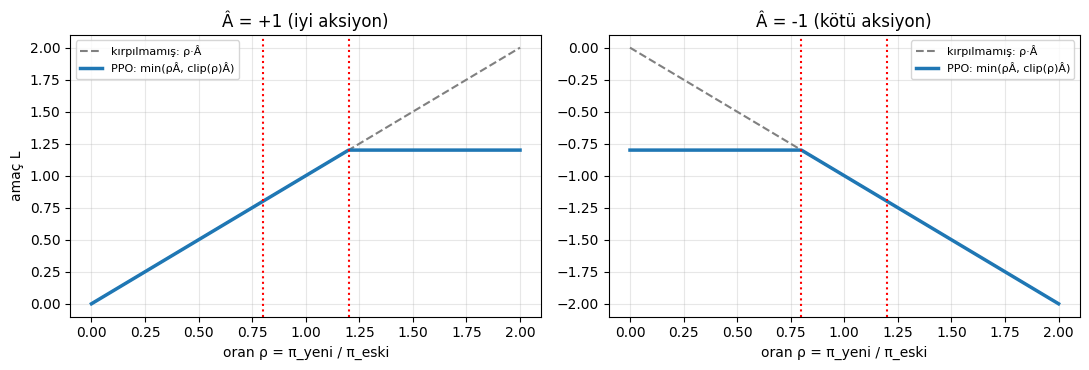

In [4]:
import matplotlib.pyplot as plt
eps = 0.2
rho = np.linspace(0, 2, 400)
L = lambda rho, A: np.minimum(rho * A, np.clip(rho, 1 - eps, 1 + eps) * A)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=False)
for a_, A_ in zip(ax, (+1.0, -1.0)):
    a_.plot(rho, rho * A_, "--", color="gray", label="kırpılmamış: ρ·Â")
    a_.plot(rho, L(rho, A_), lw=2.5, label="PPO: min(ρÂ, clip(ρ)Â)")
    a_.axvline(1 - eps, color="r", ls=":"); a_.axvline(1 + eps, color="r", ls=":")
    a_.set_title(f"Â = {A_:+.0f} ({'iyi aksiyon' if A_ > 0 else 'kötü aksiyon'})")
    a_.set_xlabel("oran ρ = π_yeni / π_eski"); a_.grid(alpha=0.3); a_.legend(fontsize=8)
ax[0].set_ylabel("amaç L"); plt.tight_layout(); plt.show()

In [5]:
rng = np.random.default_rng(0)
for nA in (2, 10, 100):
    Q1 = rng.normal(0, 1, (100_000, nA)); Q2 = rng.normal(0, 1, (100_000, nA))   # gerçek Q = 0, tahminler gürültülü
    print(f"{nA:3d} aksiyon | tek Q: E[max] = {Q1.max(1).mean():+.3f} | "
          f"iki Q (min): {np.minimum(Q1, Q2).max(1).mean():+.3f} | gerçek: 0")

  2 aksiyon | tek Q: E[max] = +0.567 | iki Q (min): -0.099 | gerçek: 0
 10 aksiyon | tek Q: E[max] = +1.537 | iki Q (min): +0.673 | gerçek: 0
100 aksiyon | tek Q: E[max] = +2.506 | iki Q (min): +1.418 | gerçek: 0
